# Titanic Survival Prediction with a Decision Tree

## 1. Imports


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, precision_score, recall_score, f1_score

## 2. Load Data and Exploratory Data Analysis(EDA)

In [3]:
df = pd.read_csv("titanic.csv")

In [ ]:
print("database shape", df.shape)
print("*" * 50)
print("mata info:", df.info())
print("*" * 50)
df.head()

#### `SibSp` = siblings + spouse
#### `Parch` = Parents + children
#### `Embarked` = Port where the passenger boarded
#### `Fare` = 	Passenger's ticket fare
#### `Cabin` = 	Cabin identification number
#### `Ticket` = Ticket number

In [ ]:
df.describe()

In [ ]:
df.columns.tolist()

In [ ]:
df.isnull().sum()

In [ ]:
(df.select_dtypes(include="number") == 0).sum()

# 3. Pre-processing # 

#### drop unnecessary columns

In [4]:
df = df.drop(["PassengerId", "Name", "Ticket", "Cabin"], axis=1)
# df = df.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])

In [ ]:
print(df.columns.tolist())
df.shape

#### Handle missing values


In [ ]:
avg_mean_by_survival = df.groupby("Survived")["Age"].mean()
print("average age based on survival:\n", avg_mean_by_survival)
print("*" * 50)

age_means = df.groupby(["Sex", "Pclass"])["Age"].mean()
print("average age based on pclass and gender:\n", age_means)

In [5]:
df["Age"] = df["Age"].fillna(df.groupby(["Sex", "Pclass"])["Age"].transform("mean"))


print(df["Age"].isnull().sum())   

0


In [ ]:
print(df["Embarked"].isnull().sum())

In [ ]:
# df = df.dropna(subset=["Embarked"])

In [ ]:
print(df["Embarked"].mode()[0])

In [6]:
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
print(df["Embarked"].isnull().sum()) 

0


#### Convert `Sex` and `Embarked` to numbers

In [ ]:
print(df.select_dtypes(exclude="number"))

# print(df.select_dtypes(include="object"))
# "object", "category", "bool", "number"


In [ ]:
print("values used in 'Embarked' column ", df["Embarked"].unique())
print(df["Embarked"].value_counts(dropna=False))

print("*" * 75)

print(df["Sex"].unique())
print(df["Sex"].value_counts(dropna=False))

In [7]:
df["Sex"] = df["Sex"].replace({"male": 0, "female": 1})


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_26432\2480131041.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["Sex"] = df["Sex"].replace({"male": 0, "female": 1})


In [8]:
df["Embarked"] = df["Embarked"].replace({"S": 0, "C": 1, "Q": 2})

# df = pd.get_dummies(df, columns=["Embarked"], drop_first=False, dtype=int)

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_26432\1133112476.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["Embarked"] = df["Embarked"].replace({"S": 0, "C": 1, "Q": 2})


In [ ]:
df.head()

### Feature engineering

\[
FamilySize = SibSp + Parch + 1
\]

In [9]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

In [ ]:
display(df.head())

In [ ]:
print("final dataset shape:", df.shape)
display(df.head(10))


print("\nchecking null values:")
print(df.isnull().sum())

## 4. Train/Test Split
Separate `Survived` (target) from the other columns, then split

In [10]:
x = df.drop("Survived", axis=1)
y = df["Survived"]

In [ ]:
print(x.columns.tolist())
print(y.name)

In [11]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state=42, stratify = y)
print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (712, 8)
Testing data: (179, 8)


## 5. Defining the Decision Tree


In [12]:
def decision_tree(criterion="gini", max_depth=None, seed=0):

    #criterians available in sklearn: "gini", "entropy", "los_loss"

    model = DecisionTreeClassifier(criterion= criterion, max_depth=max_depth, random_state=seed)

    return model

## 6. Training the Model with (Gini)

In [13]:
model = decision_tree()
model.fit(x_train, y_train)
print("Decision Tree trained successfully!")

Decision Tree trained successfully!


## 7. Prediction and Evaluation


In [14]:
y_pred = model.predict(x_test)
# print("predicted values: \n", y_pred)

In [15]:
print("predicted values: \n", y_pred[:15])

print("\nactual values: \n", y_test.values[:15])


predicted values: 
 [0 0 0 0 1 0 1 1 1 0 0 0 1 0 0]

actual values: 
 [0 0 1 0 1 1 1 0 0 0 0 0 1 0 0]


In [16]:
def evaluation(y_test, y_pred):
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred, average="macro"))
    print("Recall:", recall_score(y_test, y_pred, average="macro"))
    print("F1 Score:", f1_score(y_test, y_pred, average="macro"))


    

    # print("\nClassification Report:")
    # print(classification_report(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(7, 5))
    sns.heatmap(cm,
        annot=True,
        fmt="d",
        cmap="YlGnBu",
        xticklabels=["Not Survived", "Survived"],
        yticklabels=["Not Survived", "Survived"])

    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title("Decision Tree Confusion Matrix")

    plt.show()



Accuracy: 0.7988826815642458
Precision: 0.7874934793948878
Recall: 0.7904479578392622
F1 Score: 0.788859764089122


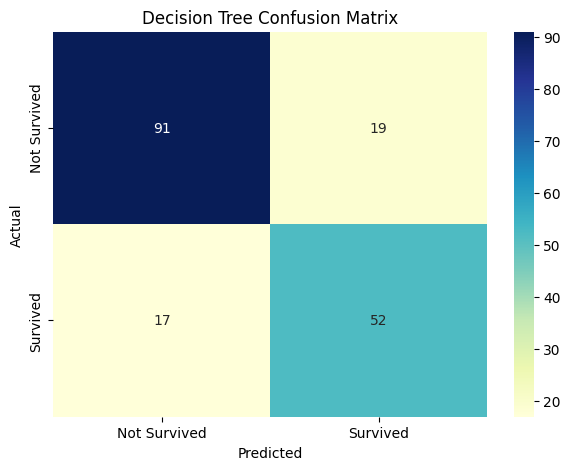

In [17]:
evaluation(y_test, y_pred)

## 8. Visualizing the Tree and Feature Importance

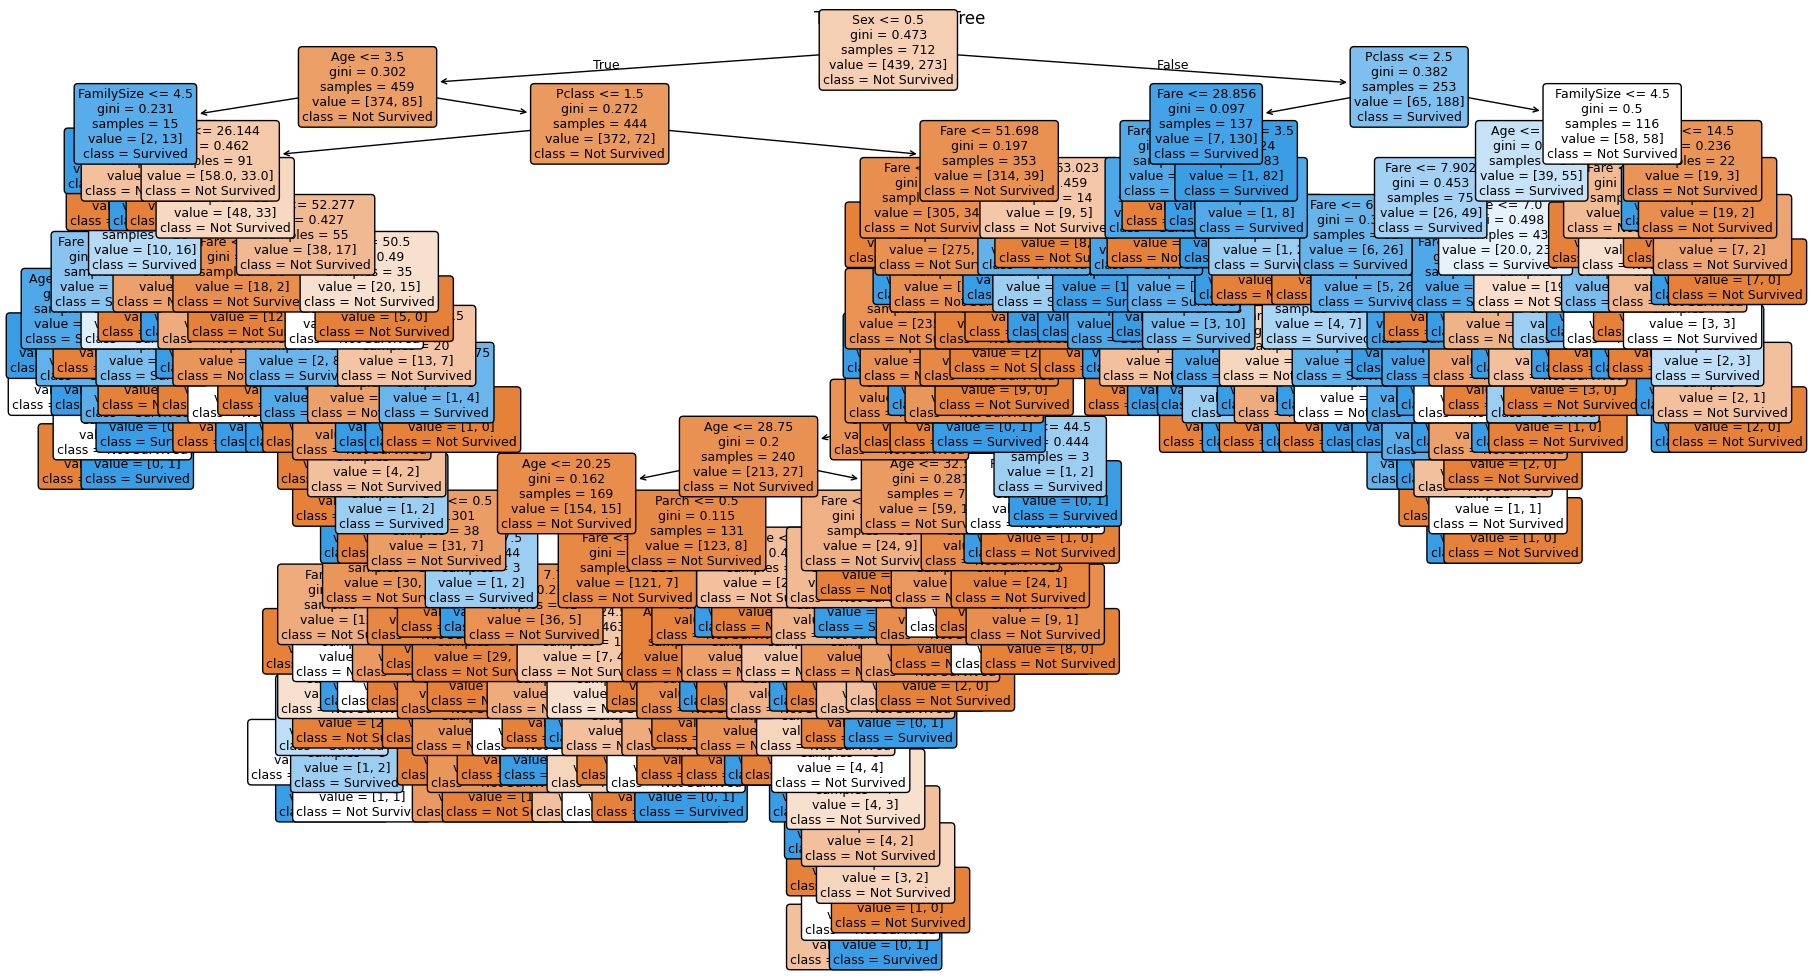

In [18]:
plt.figure(figsize=(22, 12))

plot_tree(
    model,
    feature_names=x.columns,
    class_names=["Not Survived", "Survived"],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Titanic Decision Tree")
plt.show()

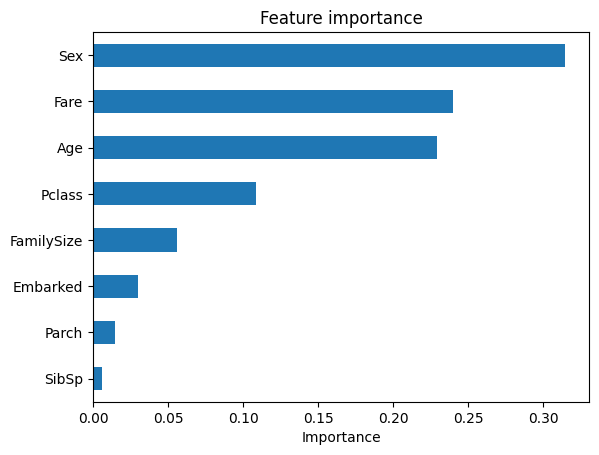

In [19]:
importance = pd.Series(model.feature_importances_, index=x.columns.tolist()).sort_values()
importance.plot(kind="barh", title="Feature importance")
plt.xlabel("Importance")
plt.show()

## 9. Predicting a New Passenger

In [20]:
new_passengers = pd.DataFrame([
    {   # male, 3rd class, travelling alone
        "Pclass": 3, "Sex": 0, "Age": 25, "SibSp": 0, "Parch": 0,
        "Fare": 7.25, "Embarked": 0, "FamilySize": 1
    },
    {   # female, 1st class, with her spouse
        "Pclass": 1, "Sex": 1, "Age": 38, "SibSp": 1, "Parch": 0,
        "Fare": 71.28, "Embarked": 1, "FamilySize": 2
    },
    {   # boy, 2nd class, with a sibling and two parents
        "Pclass": 2, "Sex": 0, "Age": 8, "SibSp": 1, "Parch": 2,
        "Fare": 30.0, "Embarked": 2, "FamilySize": 4
    },
])

display(new_passengers)


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,FamilySize
0,3,0,25,0,0,7.25,0,1
1,1,1,38,1,0,71.28,1,2
2,2,0,8,1,2,30.00,2,4


In [21]:
predictions = model.predict(new_passengers)

for i in range(len(predictions)):
    if predictions[i] == 1:
        print(f"Passenger {i + 1}: Survived")
    else:
        print(f"Passenger {i + 1}: Did not survive")


Passenger 1: Did not survive
Passenger 2: Survived
Passenger 3: Did not survive


### Decision path
Trace which splits the new passenger follows down to the final leaf.

In [22]:
# Get the nodes visited by our passenger
node_indicator = model.decision_path(new_passengers)

# Get the final leaf node
leaf_id = model.apply(new_passengers)[0]

# Extract node IDs
node_ids = node_indicator.indices[
    node_indicator.indptr[0]:
    node_indicator.indptr[1]
]

print("Decision Path:\n")

for node_id in node_ids:

    if node_id == leaf_id:
        print(f"Node {node_id}: LEAF NODE")
        continue

    feature_index = model.tree_.feature[node_id]
    threshold = model.tree_.threshold[node_id]

    feature_name = x.columns[feature_index]
    feature_value = new_passengers.iloc[0, feature_index]

    if feature_value <= threshold:
        decision = "<="
    else:
        decision = ">"

    print(
        f"Node {node_id}: "
        f"{feature_name} ({feature_value}) "
        f"{decision} {threshold:.2f}"
    )

print("\nFinal Leaf:", leaf_id)

Decision Path:

Node 0: Sex (0) <= 0.50
Node 1: Age (25) > 3.50
Node 7: Pclass (3) > 1.50
Node 61: Fare (7.25) <= 51.70
Node 62: Fare (7.25) > 7.13
Node 64: Fare (7.25) > 7.18
Node 66: Fare (7.25) <= 23.35
Node 67: Age (25) > 13.50
Node 69: Fare (7.25) <= 22.89
Node 70: Age (25) <= 45.25
Node 71: Age (25) <= 43.50
Node 72: Age (25) <= 28.75
Node 73: Age (25) > 20.25
Node 95: Parch (0) <= 0.50
Node 96: Fare (7.25) <= 7.80
Node 97: Fare (7.25) <= 7.74
Node 98: Fare (7.25) > 7.24
Node 106: LEAF NODE

Final Leaf: 106


## 10. Comparing with the Entropy Criterion
Train a second tree using `entropy` instead of `gini`. 

In [23]:
model_entropy = decision_tree(criterion="entropy")
model_entropy.fit(x_train, y_train)
print("Entropy Decision Tree trained successfully!")

Entropy Decision Tree trained successfully!


Accuracy: 0.7597765363128491
Precision: 0.7468198338525441
Recall: 0.7505270092226615
F1 Score: 0.748439389482629


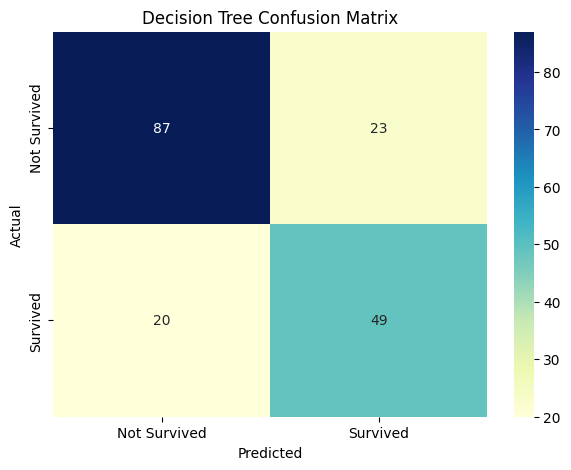

In [24]:
y_pred_entropy = model_entropy.predict(x_test)
evaluation(y_test, y_pred_entropy)

In [27]:
prediction = model_entropy.predict(new_passengers)[0]
probabilities = model_entropy.predict_proba(new_passengers)[0]

print("Prediction:", "Survived" if prediction == 1 else "Did not survive")


Prediction: Did not survive
